The challenge states as follows:
Given a diagonal matrix D with 1s and -1s on the diagonal, where the diagonal elements are determined by
 an array d, create a quantum circuit that applies the matrix D to a quantum state.
In other words, finding the equivalent quantum circuit that applies the same transformation as 
the matrix D on a quantum state.


In [1]:
import qiskit
from qiskit import QuantumCircuit
from qiskit_aer import Aer

In [13]:
#create a matrix with numpy
#this matrix is a diagonal matrix with 1s and -1s on the diagonal. The diagonal elements are determined by the array d, which is created using numpy's ones function and then modified to have -1s at specific indices.
import numpy as np

n = 3
d = np.ones(2**n)          # [1, 1, 1, 1, 1, 1, 1, 1]
d[[  1 , 2 , 6]] = -1       # columns 0, 5, 6, 7 get -1

D = np.diag(d)
print(D.astype(int))

[[ 1  0  0  0  0  0  0  0]
 [ 0 -1  0  0  0  0  0  0]
 [ 0  0 -1  0  0  0  0  0]
 [ 0  0  0  1  0  0  0  0]
 [ 0  0  0  0  1  0  0  0]
 [ 0  0  0  0  0  1  0  0]
 [ 0  0  0  0  0  0 -1  0]
 [ 0  0  0  0  0  0  0  1]]


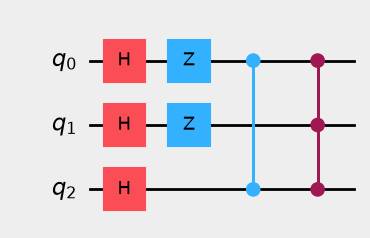

In [14]:
#create the quantum ciruit
qc = QuantumCircuit(n)
#add a global phase to all states in the circuit.
#here we just added the Hadamaed gate for each qubit to create a superposition of all possible states.
#This allows to see the effect of the diagonal matrix on all states in the circuit.
for i in range(n):
    qc.h(i)
if d[0] == -1:
    qc.z(0)
    qc.x(0) 
    qc.z(0)
    qc.x(0)

import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import ZGate


def apply_diagonal(qc, d, n):
    qubits = list(range(n))
    #number of states in the circuit
    N = 2**n

    # f[x] = 1 where the diagonal entry is -1
    c = [1 if v == -1 else 0 for v in d]

    # truth table -> list of needed gates (c[S] = 1 means "a gate on the 1-bits of S")
    #basically here we iterate for every binary string or state all the n positions
    #we check if the ith position is one and apply the xor operation to the current state and the state with the ith bit flipped

    for i in range(n):
        for x in range(N):
            if x >> i & 1:
                c[x] ^= c[x ^ (1 << i)]
    #for each state we check if the corresponding entry in c is 1, if it is we apply a Z gate to the qubits corresponding to the 1-bits of the state. If there is only one qubit we apply a Z gate, if there are two qubits we apply a controlled Z gate, and if there are more than two qubits we apply a multi-controlled Z gate.
    for S in range(N):
        if not c[S]:
            continue
        targets = [qubits[i] for i in range(n) if S >> i & 1]   # the 1-bits of S
        k = len(targets)
        if k == 0:
            pass
        elif k == 1:
            qc.z(targets[0])
        else:
            qc.append(ZGate().control(k - 1), targets)          # CZ, CCZ, CCCZ, ...
    return qc

apply_diagonal(qc, d, n)
qc.draw('mpl', style={'backgroundcolor': '#EEEEEE', 'plot_barriers': False, 'dpi': 100})

# From a diagonal ±1 matrix to a quantum circuit
Okey, so this is an interesting solution that Claude proposed to me actually :

**Goal:** build a circuit for a diagonal matrix $D=\mathrm{diag}(d_0,\dots,d_{2^n-1})$ with $d_x\in\{+1,-1\}$.

$$D|x\rangle=(-1)^{f(x)}|x\rangle,\qquad f(x)=\begin{cases}1 & d_x=-1\\ 0 & d_x=+1\end{cases}$$

So the circuit only has to **flip the sign of the basis states where $f(x)=1$**.

---

## 1. Z gates are XORs (in the exponent)

A Z gate acts on a basis state as

$$Z|x\rangle=(-1)^{x}|x\rangle .$$

The sign is $(-1)^{\text{bit}}$. When we apply several gates, the signs multiply, so the exponents add modulo 2, and addition modulo 2 is XOR:

$$(-1)^a\cdot(-1)^b=(-1)^{a\oplus b}.$$

**Consequence:** if $f=t_1\oplus t_2\oplus\dots\oplus t_k$, then $(-1)^{f}=(-1)^{t_1}\cdots(-1)^{t_k}$.
Each XOR term $t_j$ can therefore be implemented by **its own gate**, and the gates are simply applied one after another.

---

## 2. Any binary function is an XOR of products of bits (ANF)

**Claim.** Every $f:\{0,1\}^n\to\{0,1\}$ can be written as

$$f(x)=a_0\oplus a_1x_0\oplus a_2x_1\oplus a_3x_0x_1\oplus a_4x_2\oplus\dots\oplus a_{2^n-1}x_0x_1\cdots x_{n-1},\qquad a_m\in\{0,1\}.$$
And that's the main trick, we will then translate this ANF expression into a series of Z gates or control Z gates.

(Index $m$ selects the monomial made of the qubits whose bit is 1 in $m$. For example $m=6=110_2$ is $x_1x_2$.)

**Why it is always possible**

1. *Detector for one input $s$:* $\delta_s(x)=\prod_i(x_i\text{ if }s_i=1,\ \ 1\oplus x_i\text{ if }s_i=0)$. It equals 1 only at $x=s$.
2. *Combine them:* $f(x)=\bigoplus_{s:\,f(s)=1}\delta_s(x)$. At most one detector fires at any $x$, so XOR is enough.
3. *Expand* the products. Use $x_i x_i=x_i$ (no powers) and $a\oplus a=0$ (repeated terms cancel). What is left is a XOR of distinct monomials.

There are $2^{2^n}$ possible monomial choices and $2^{2^n}$ Boolean functions, so the representation is **unique**.

**How to find the coefficients (Möbius transform)**

A monomial is "switched on" at input $s$ only if all its variables are 1, i.e. $m\subseteq s$:

$$f(s)=\bigoplus_{m\subseteq s}a_m\quad\Longleftrightarrow\quad a_m=\bigoplus_{s\subseteq m}f(s).$$

(Subset means: the 1-bits of one number are among the 1-bits of the other.)

Now one question might arise , why caring about these subsets ? The answer is simple : Imagine you are applying a Z gate to turn a state |001> into -|001> , for that we need to apply a Z gate on the qubit_0 , this operation will then impact all the states that got the first bit as 0. So for each state, you need to check for the other states that share the same subsets of binary string : 
For example 110 , will be impacted by 100 , 010 
111 by : 110 , 100 , 011 , 001, 101.

The loop below computes all $a_m$ in $n\cdot 2^n$ steps, one bit

# Flipping the solutions vs. flipping the non-solutions: same circuit

## The idea in one sentence

"Start with all states flipped, then un-flip the non-solutions" and "start with nothing flipped, then flip the solutions" give **the same gates**. The only difference is a global phase of -1, which needs no gate on the qubits.

## Step by step

**Path A (flip the solutions):**
every state starts at +. We flip the sign of each solution.
Result: solutions have -1, non-solutions have +1. This is D.

**Path B (flip everything, then un-flip the non-solutions):**
1. Flip the sign of *all* states. This is a global factor of -1. It is just a phase, so it costs **no gates**.
2. Flip the sign of the non-solutions again, which brings them back to +.
   Result: solutions have -1, non-solutions have +1. This is also D.

Both paths end with the same matrix D.

## Why the gates are the same

In Path B, the only thing that costs gates is step 2: flipping the non-solutions.
In Path A, the only thing that costs gates is flipping the solutions.

We just showed that both paths give D. The global -1 in Path B is free, so:

> gates that flip the solutions = gates that flip the non-solutions (up to a global -1)

That is why you get the same circuit either way. Flipping all states changes nothing in the gates, it only adds a global -1.

## Small example (2 qubits)

Target: only the state 11 is a solution, so D = (+, +, +, -).

**Path A:** flip 11 with a CZ.

| state | start | after CZ |
|---|---|---|
| 00 | + | + |
| 01 | + | + |
| 10 | + | + |
| 11 | + | - |

**Path B:** flip everything (global -1), then flip 00, 01, 10 back.
Flipping exactly {00, 01, 10} is the same as a CZ followed by a global -1
(CZ gives (+, +, +, -), and an extra global -1 gives (-, -, -, +), which is the pattern that flips 00, 01, 10 and not 11).

| state | start | flip everything | flip {00, 01, 10} | final |
|---|---|---|---|---|
| 00 | + | - | + | + |
| 01 | + | - | + | + |
| 10 | + | - | + | + |
| 11 | + | - | - | - |

Both paths end at (+, +, +, -) = D. The only gate acting on the qubits in both paths is the **same CZ**. The two global -1 factors in Path B (one from "flip everything", one hidden inside "flip {00, 01, 10}") cancel each other.

## The rule

- Flipping the solutions, or flipping the non-solutions, uses the same Z / CZ / CCZ gates.
- The two circuits differ only by a global phase of -1.
- A global phase is physically invisible, but keep it if you compare matrices exactly or build a controlled version.

## Why the code does it automatically

The Mobius loop only computes which monomials appear in f. Complementing f (turning solutions into non-solutions) changes only the constant term c[0], which is the global phase. All the other c[S], and therefore all the gates, stay the same.

In [17]:
#measure the amplitudes of the states in the circuit

from qiskit.quantum_info import Statevector

# circuit = H on all qubits, then your diagonal circuit

sv = Statevector(qc)         # exact simulation, no shots
N = 2**n
# amplitude of each basis state
for x in range(N):
    bits = format(x, f"0{n}b")             # x2 x1 x0, same convention as before
    print(f"|{bits}>  amplitude = {sv.data[x]:.4f}")


#print the matrix
print("Matrix D:")
print(D.astype(int))

|000>  amplitude = 0.3536+0.0000j
|001>  amplitude = -0.3536+0.0000j
|010>  amplitude = -0.3536+0.0000j
|011>  amplitude = 0.3536+0.0000j
|100>  amplitude = 0.3536+0.0000j
|101>  amplitude = 0.3536+0.0000j
|110>  amplitude = -0.3536+0.0000j
|111>  amplitude = 0.3536+0.0000j
Matrix D:
[[ 1  0  0  0  0  0  0  0]
 [ 0 -1  0  0  0  0  0  0]
 [ 0  0 -1  0  0  0  0  0]
 [ 0  0  0  1  0  0  0  0]
 [ 0  0  0  0  1  0  0  0]
 [ 0  0  0  0  0  1  0  0]
 [ 0  0  0  0  0  0 -1  0]
 [ 0  0  0  0  0  0  0  1]]
